# Phase 2: training one shared, decentralized policy

One small MLP, copied onto every drone, maps what that drone sees to an acceleration. It is trained on a grid of swarm sizes (8 to 64 drones) and goal counts (8 to 128), by backpropagating the formation loss through the simulator, and scored against the per-scene optimum (the Phase 1 method applied to each test scene).

The math is in `docs/walkthrough/phase2.html`. All code is imported from `swarm/`. Training takes about 20–25 minutes on a laptop CPU; set `TRAIN = False` to reuse `runs/phase2/best.pt`.

| Section | What it shows |
|---|---|
| 1 | Setup |
| 2 | The data: drones × goals grid and the fixed benchmark |
| 3 | What one drone sees |
| 4 | Training, with live curves |
| 5 | Results: ratio to the per-scene optimum, every cell |
| 6 | Every cell and shape, side by side with the optimum |
| 7 | Held-out shapes, including "MARRY ME" |
| 8 | Self-healing: drones removed mid-flight |
| 9 | Policy vs the Phase 1 fixed plan |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import shutil
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, clear_output, display

from swarm import viz
from swarm.config import load_config
from swarm.dataset import GRID, HELDOUT_FAMILIES, TRAIN_FAMILIES, build_benchmark, load_cell, make_scene
from swarm.losses import chamfer
from swarm.observations import _knn_idx, goal_occupancy, knn_offsets
from swarm.plan import optimize_plan
from swarm.policy import SharedMLP, policy_from_config
from swarm.sim import rollout, rollout_closed_loop, rollout_with_removal
from swarm.train import evaluate_benchmark, evaluate_cell, overall_ratio, train

cfg = load_config("configs/default.yaml")
TRAIN = True                                 # False: load runs/phase2/best.pt instead of training
REBUILD_BENCHMARK = False                    # True: regenerate data/benchmark (about 3 minutes)
RUN = Path("runs/phase2")
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
print("parameters:", sum(p.numel() for p in policy_from_config(cfg).parameters()))

parameters: 6850


## 2. The data

Every iteration trains on a random cell (N drones, M goals) of the grid below, with fresh random scenes. A scene passes a **feature-size check**: parts of the shape far apart along the outline must be at least one drone spacing apart in space, so the swarm can actually draw it. Each scene's collision distance is **d_min = 0.4 × drone spacing** (outline length ÷ N).

The fixed **benchmark** (`data/benchmark/`) is what every method is scored on: 32 scenes of training families and up to 16 of held-out families per cell, each with its **per-scene optimum**, found by optimizing that scene's accelerations directly with the same collision penalty.

In [2]:
if REBUILD_BENCHMARK or not Path("data/benchmark/index.json").exists():
    build_benchmark(cfg)
import json
index = json.loads(Path("data/benchmark/index.json").read_text())
print(f"{'cell':>14s}{'split':>9s}{'scenes':>8s}{'optimum':>11s}{'close pairs':>13s}  families skipped")
for r in index:
    print(f"  N={r['n']:3d} M={r['m']:4d}{r['split']:>9s}{r['scenes']:8d}{r['oracle_chamfer']:11.6f}{r['oracle_close_pairs']:13.2f}  {', '.join(r['skipped'])}")
print("training families:", TRAIN_FAMILIES)
print("held-out families:", HELDOUT_FAMILIES)

          cell    split  scenes    optimum  close pairs  families skipped
  N=  8 M=   8    train      32   0.002089         0.97  
  N=  8 M=   8  heldout       4   0.004139         0.75  star, spiral, word
  N=  8 M=  16    train      32   0.004212         0.06  
  N=  8 M=  16  heldout       4   0.007578         0.00  star, spiral, word
  N=  8 M=  32    train      32   0.003897         0.03  
  N=  8 M=  32  heldout       4   0.005194         0.00  star, spiral, word
  N=  8 M=  64    train      32   0.003291         0.00  
  N=  8 M=  64  heldout       4   0.005200         0.00  star, spiral, word
  N= 16 M=  16    train      32   0.000606         2.03  
  N= 16 M=  16  heldout      12   0.001295         2.67  spiral
  N= 16 M=  32    train      32   0.001056         0.12  
  N= 16 M=  32  heldout      12   0.001770         0.17  spiral
  N= 16 M=  64    train      32   0.000853         0.12  
  N= 16 M=  64  heldout      12   0.001501         0.17  spiral
  N= 32 M=  32    train 

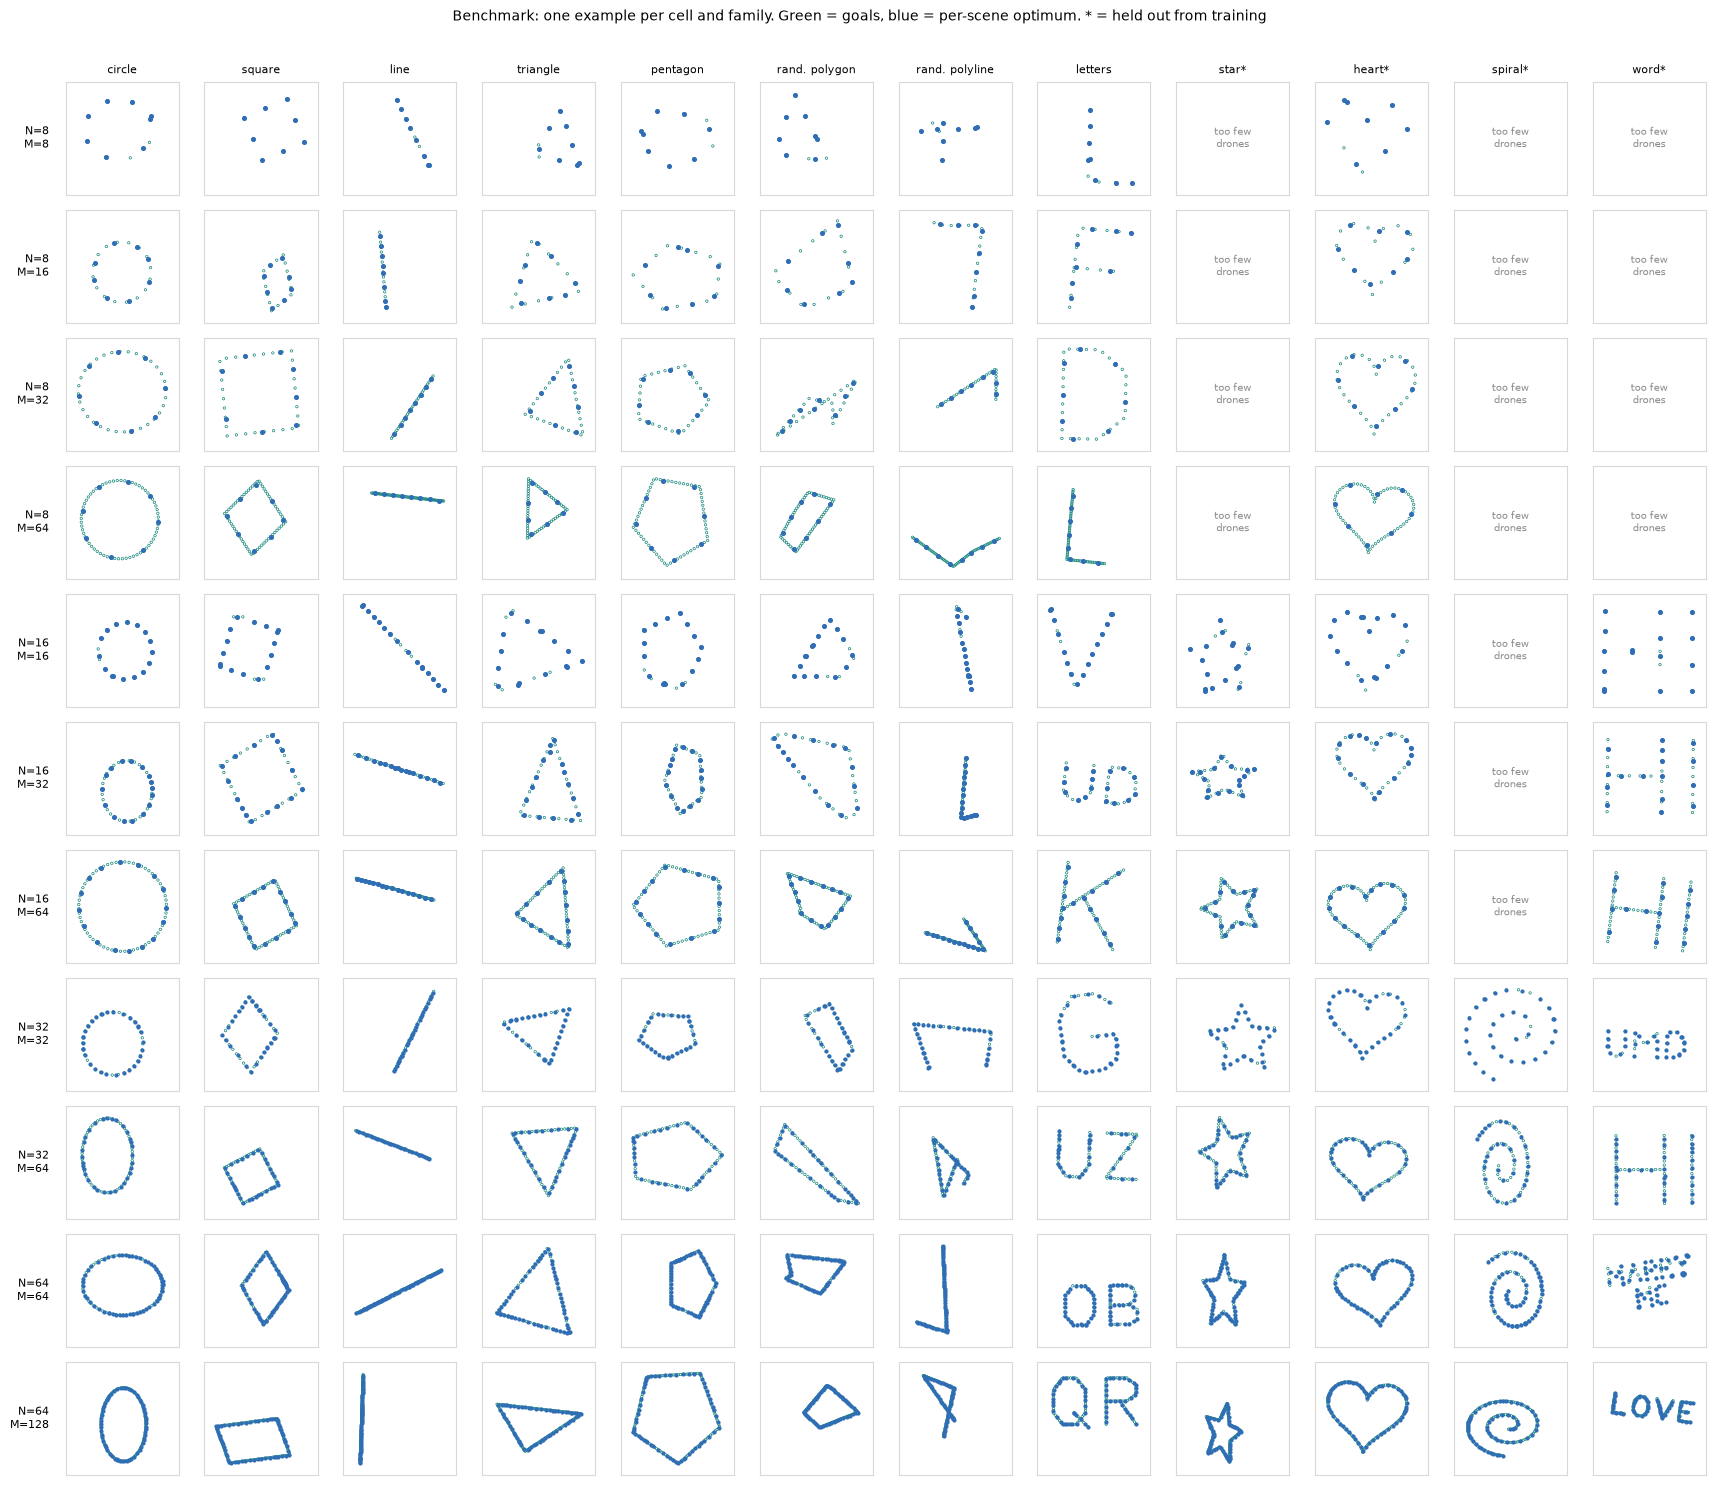

In [3]:
fig = viz.plot_benchmark_overview(FIGS / "phase2_benchmark.png")
plt.show()

## 3. What one drone sees

The blue drone sees its 6 nearest drones (orange), its 8 nearest goals (green), and for each of those goals **how close the nearest other drone is** (a small number = taken, go elsewhere). Plus the scene's d_min and its own velocity: 39 numbers, whatever the swarm size.

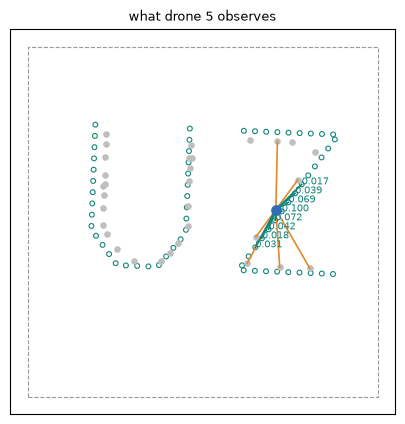

d_min for this scene: 0.0248   (goal labels: distance from that goal to the nearest other drone)


In [4]:
cell = load_cell(32, 64, "train")
s = cell["family"].index("letters")
pos, Q1 = cell["oracle_final"][s:s + 1] * 0.9, cell["goals"][s:s + 1]       # drones near (not on) the goals
i = 5
nb = knn_offsets(pos, pos, cfg.policy.k_neighbors, exclude_self=True)[0, i]
gidx = _knn_idx(pos, Q1, cfg.policy.m_targets, False)
occ = goal_occupancy(pos, Q1, gidx)[0, i]
p = pos[0, i]
fig, ax = plt.subplots(figsize=(5, 5))
viz._setup(ax, Q1[0], "what drone 5 observes")
ax.scatter(*pos[0].T, s=14, color="0.75", zorder=2)
for o in nb:
    ax.plot(*torch.stack([p, p + o]).T, color="#E08A2C", lw=1.2)
for j, o in enumerate(Q1[0, gidx[0, i]] - p):
    ax.plot(*torch.stack([p, p + o]).T, color="#13867A", lw=1.2)
    ax.annotate(f"{occ[j]:.3f}", (p + o).tolist(), fontsize=7, color="#13867A")
ax.scatter(*p, s=45, color="#2F6DB5", zorder=4)
plt.show()
print(f"d_min for this scene: {cell['d_min'][s]:.4f}   (goal labels: distance from that goal to the nearest other drone)")

## 4. Training

Each iteration: pick a grid cell → 32 random scenes → closed-loop rollout (observe → policy → `sim.step`) → loss (shape over the last 20% of steps + collision + effort, each scene divided by its spacing² so all cells weigh the same) → backward through every step → clip → Adam. Rollouts grow 40 → 70 → 100 steps; the learning rate decays with a cosine schedule.

The curve that matters is green: the benchmark score as a multiple of the per-scene optimum (1× = as good as optimizing each test scene directly).

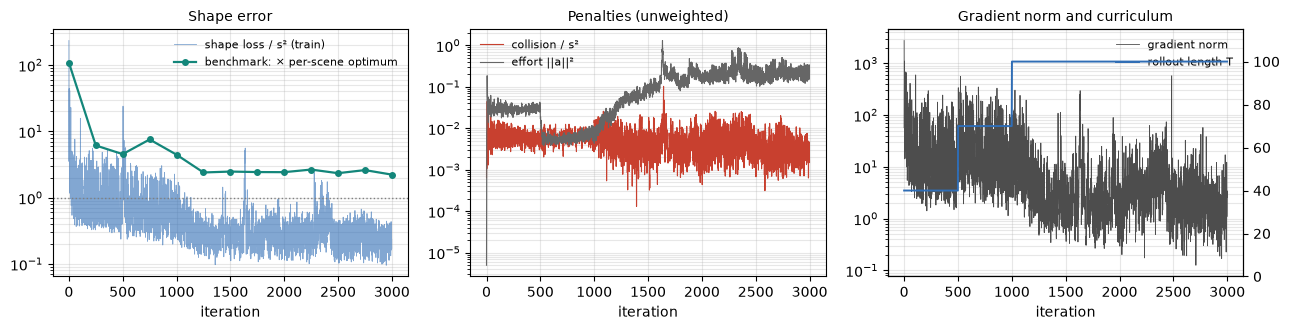

iteration 3000/3000   cell N=8 M=16   T=100   benchmark 2.23x optimum (it 3000)   16.0 min


best checkpoint: iteration 3000, benchmark 2.23x optimum -> results/models/phase2_policy.pt


In [5]:
def live(history):
    clear_output(wait=True)
    viz.plot_training(history)
    plt.show()
    tr, val = history["train"][-1], history["val"][-1]
    print(f"iteration {tr['it'] + 1}/{cfg.train.iters}   cell N={tr['n']} M={tr['m']}   T={tr['T']}   "
          f"benchmark {val['ratio']:.2f}x optimum (it {val['it']})   {tr['time'] / 60:.1f} min")

if TRAIN:
    policy, history = train(cfg, run_dir=RUN, callback=live, callback_every=100)
    viz.plot_training(history, path=FIGS / "phase2_training.png")
    plt.close()
else:
    history = json.loads((RUN / "history.json").read_text())
    display(Image(filename=FIGS / "phase2_training.png"))

ckpt = torch.load(RUN / "best.pt", weights_only=False)
policy = SharedMLP.load(RUN / "best.pt").eval()
Path("results/models").mkdir(parents=True, exist_ok=True)
shutil.copy(RUN / "best.pt", "results/models/phase2_policy.pt")       # tracked by git (runs/ is not)
print(f"best checkpoint: iteration {ckpt['it']}, benchmark {ckpt['val_ratio']:.2f}x optimum "
      f"-> results/models/phase2_policy.pt")

## 5. Results: every cell, training shapes vs held-out shapes

Geometric mean over each cell's scenes of (policy Chamfer ÷ per-scene optimum), both plus a floor of 1% of spacing² so errors far smaller than a drone spacing don't count. 1× = as good as optimizing each test scene directly.

overall (all cells): untrained 108.9x  ->  trained 2.23x (training shapes), 2.25x (held-out shapes)

          cell  train ×opt  held-out ×opt  close pairs  optimum close
  N=  8 M=   8        6.47           4.74         0.66           0.97
  N=  8 M=  16        1.53           1.47         0.25           0.06
  N=  8 M=  32        1.42           1.33         0.22           0.03
  N=  8 M=  64        1.30           1.31         0.03           0.00
  N= 16 M=  16        4.58           6.00         2.44           2.03
  N= 16 M=  32        1.70           1.61         1.78           0.12
  N= 16 M=  64        1.44           1.36         1.06           0.12
  N= 32 M=  32        2.92           3.41         7.50           5.81
  N= 32 M=  64        1.63           1.74         3.75           0.41
  N= 64 M=  64        3.02           3.31        25.91          11.72
  N= 64 M= 128        2.29           2.36        25.00           1.06


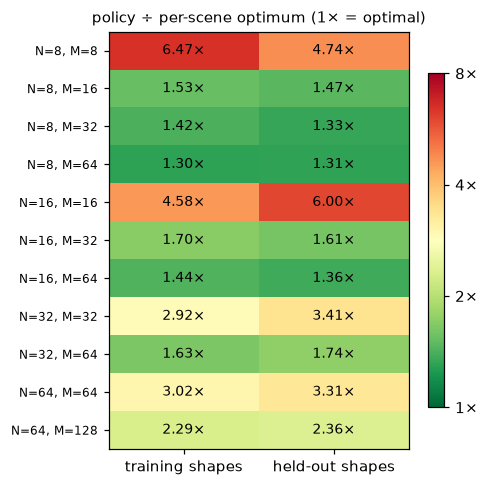

In [6]:
untrained = policy_from_config(cfg).eval()
rows = {sp: evaluate_benchmark(policy, cfg, sp) for sp in ("train", "heldout")}
rows0 = evaluate_benchmark(untrained, cfg, "train")
print(f"overall (all cells): untrained {overall_ratio(rows0):.1f}x  ->  trained {overall_ratio(rows['train']):.2f}x "
      f"(training shapes), {overall_ratio(rows['heldout']):.2f}x (held-out shapes)\n")
print(f"{'cell':>14s}{'train ×opt':>12s}{'held-out ×opt':>15s}{'close pairs':>13s}{'optimum close':>15s}")
for a, b in zip(rows["train"], rows["heldout"]):
    print(f"  N={a['n']:3d} M={a['m']:4d}{a['ratio']:12.2f}{b['ratio']:15.2f}{a['close_pairs']:13.2f}{a['oracle_close_pairs']:15.2f}")
fig = viz.plot_ratio_grid({"training shapes": rows["train"], "held-out shapes": rows["heldout"]},
                          FIGS / "phase2_ratio_grid.png", title="policy ÷ per-scene optimum (1× = optimal)")
plt.show()

## 6. Every cell and shape: policy final positions (compare with the optimum figure in section 2)

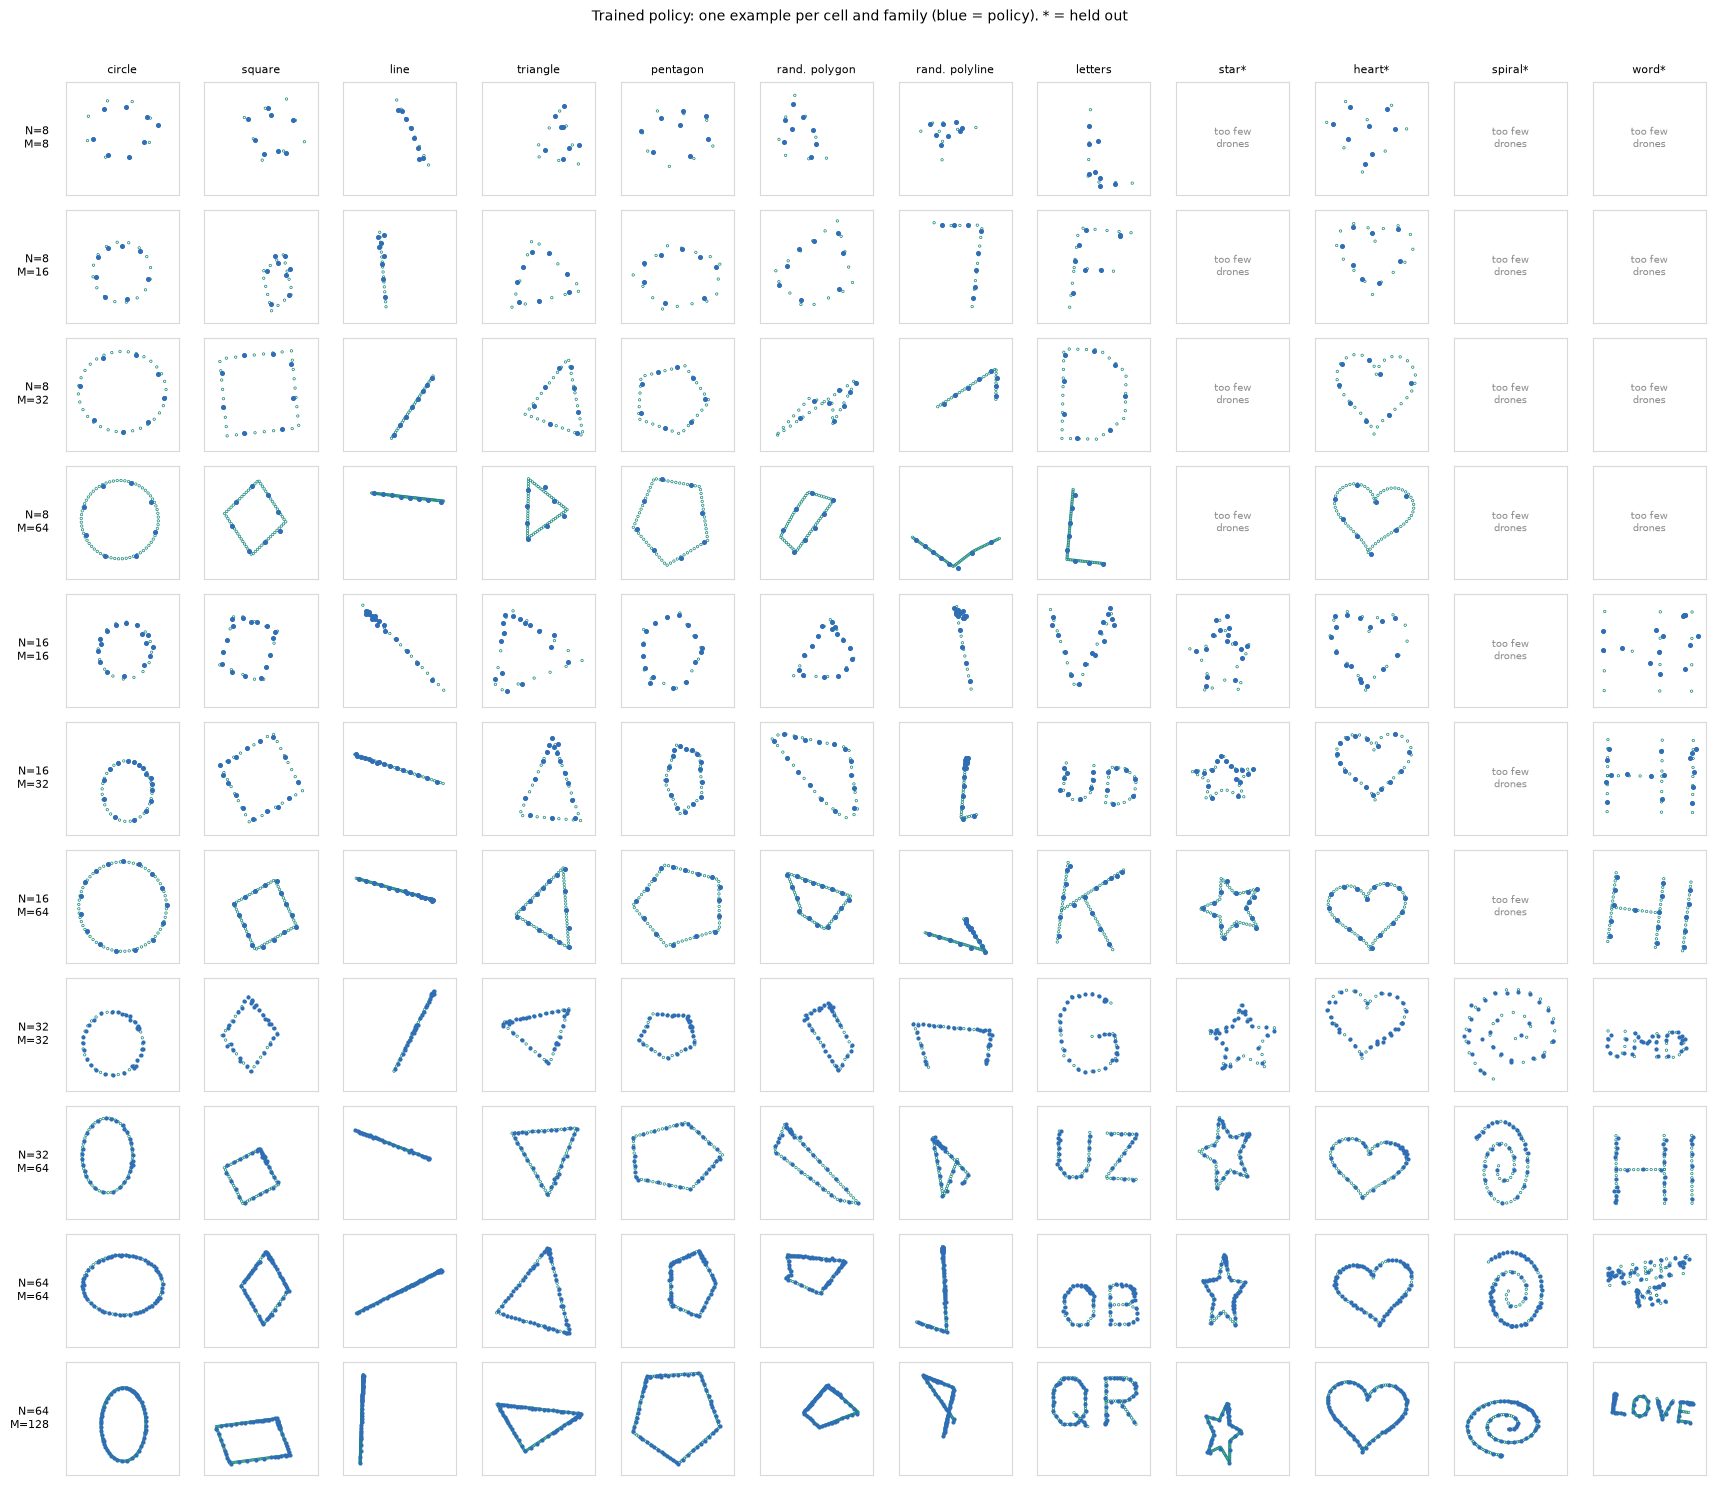

In [7]:
finals = {}
for n, m in GRID:
    for sp in ("train", "heldout"):
        finals[(n, m, sp)] = evaluate_cell(policy, load_cell(n, m, sp), cfg)["traj"][:, -1]
fig = viz.plot_benchmark_overview(FIGS / "phase2_policy_overview.png", finals=finals,
                                  title="Trained policy: one example per cell and family (blue = policy). * = held out")
plt.show()

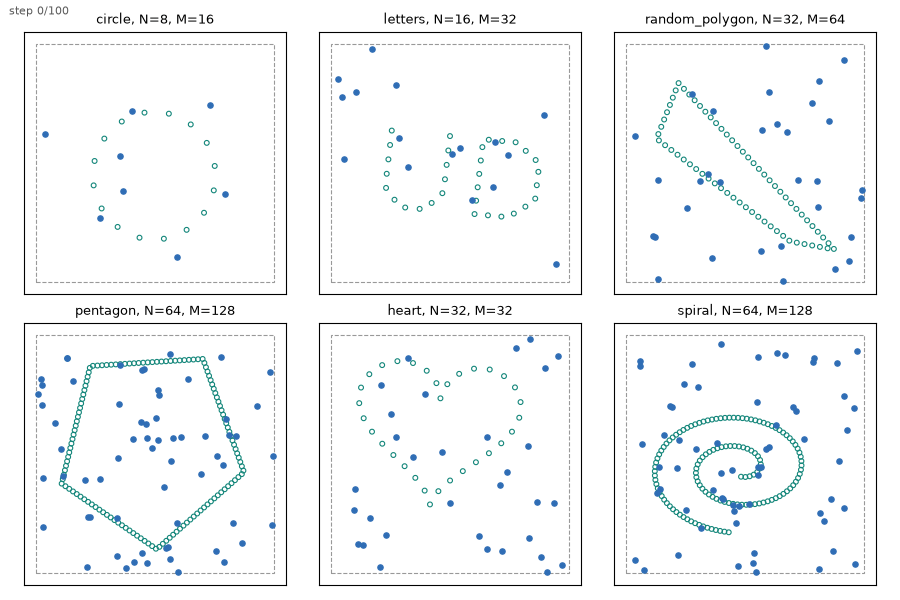

In [8]:
picks = [(8, 16, "train", "circle"), (16, 32, "train", "letters"), (32, 64, "train", "random_polygon"),
         (64, 128, "train", "pentagon"), (32, 32, "heldout", "heart"), (64, 128, "heldout", "spiral")]
trajs, goals, titles = [], [], []
for n, m, sp, fam in picks:
    c = load_cell(n, m, sp); i = c["family"].index(fam)
    sub = {k: c[k][i:i + 1] for k in ("start", "goals", "d_min", "oracle_chamfer")}
    trajs.append(evaluate_cell(policy, sub, cfg)["traj"][0]); goals.append(c["goals"][i])
    titles.append(f"{fam}, N={n}, M={m}")
gif = viz.save_gif_grid(trajs, goals, GIFS / "phase2_cells.gif", titles=titles, cols=3, panel=3.0)
display(Image(filename=gif))

## 7. Held-out shapes, including MARRY ME

Stars, hearts, spirals and words were never in training. Each drone only sees nearby goals, so it does not need to know which shape it is in.

MARRY ME Chamfer: 0.000476


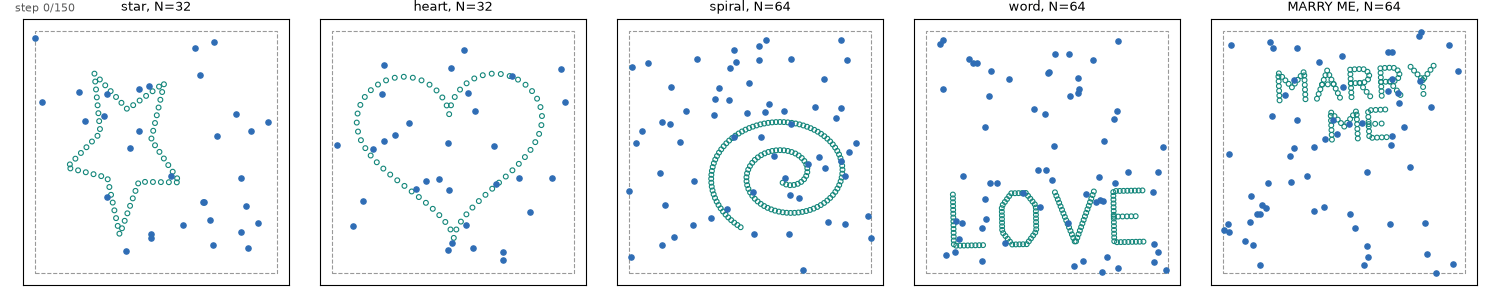

In [9]:
rng = np.random.default_rng(3)
demo = [("star", 32, 64), ("heart", 32, 64), ("spiral", 64, 128), ("word", 64, 128)]
trajs, goals, titles = [], [], []
for fam, n, m in demo:
    sc = make_scene(fam, n, m, rng)
    t = lambda k: torch.tensor(np.asarray(sc[k])[None], dtype=torch.float32)
    tr, _ = rollout_closed_loop(t("start"), torch.zeros_like(t("start")), t("goals"), torch.tensor([sc["d_min"]]),
                                policy.act, cfg, steps=150)
    trajs.append(tr[0].detach()); goals.append(t("goals")[0]); titles.append(f"{fam}, N={n}")
# MARRY ME explicitly, 64 drones on 128 goals
from swarm.dataset import text_strokes, transform, sample_strokes, total_length, D_MIN_FRAC
st = transform(text_strokes("MARRY\nME"), np.random.default_rng(0), upright=True)
Qm = torch.tensor(sample_strokes(st, 128)[None], dtype=torch.float32)
p0 = torch.rand(1, 64, 2, generator=torch.Generator().manual_seed(0)) - 0.5
dm = torch.tensor([D_MIN_FRAC * total_length(st) / 64])
with torch.no_grad():
    tr, _ = rollout_closed_loop(p0, torch.zeros_like(p0), Qm, dm, policy.act, cfg, steps=150)
trajs.append(tr[0]); goals.append(Qm[0]); titles.append("MARRY ME, N=64")
print("MARRY ME Chamfer:", round(chamfer(tr[:, -1], Qm).item(), 6))
gif = viz.save_gif_grid(trajs, goals, GIFS / "phase2_heldout.gif", titles=titles, cols=5, panel=3.0)
display(Image(filename=gif))

## 8. Self-healing: a quarter of the drones removed at step 60

Nobody is told. The remaining drones stop seeing them as neighbours, see their goals become free, and spread out.

circle   Chamfer before removal (step 60) 0.00046   just after (61) 0.00090   end (160) 0.00062
letters  Chamfer before removal (step 60) 0.00083   just after (61) 0.00174   end (160) 0.00095


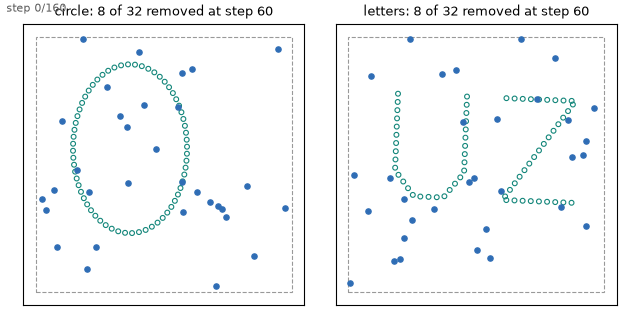

In [10]:
trajs, goals, heal = [], [], {}
for fam in ("circle", "letters"):
    c = load_cell(32, 64, "train"); i = c["family"].index(fam)
    p0, Qh, dm = c["start"][i:i + 1], c["goals"][i:i + 1], c["d_min"][i:i + 1]
    keep = torch.ones(32, dtype=torch.bool); keep[torch.randperm(32, generator=torch.Generator().manual_seed(1))[:8]] = False
    frames = rollout_with_removal(p0, torch.zeros_like(p0), Qh, dm, policy.act, cfg, steps=160, remove_at=60, keep=keep)
    heal[fam] = [chamfer(frames[t][None], Qh).item() for t in (60, 61, 160)]
    trajs.append(frames); goals.append(Qh[0])
for fam, (a, b, c_) in heal.items():
    print(f"{fam:8s} Chamfer before removal (step 60) {a:.5f}   just after (61) {b:.5f}   end (160) {c_:.5f}")
gif = viz.save_gif_grid(trajs, goals, GIFS / "phase2_self_healing.gif",
                        titles=[f"{f}: 8 of 32 removed at step 60" for f in heal], cols=2, panel=3.2)
display(Image(filename=gif))

## 9. Policy vs the Phase 1 fixed plan

The plan is optimized once for start 0 and replayed from 15 other starts; the policy just runs.

In [11]:
c = load_cell(32, 64, "train"); i = c["family"].index("circle")
Qc, dm = c["goals"][i:i + 1], c["d_min"][i:i + 1]
starts = torch.rand(16, 32, 2, generator=torch.Generator().manual_seed(0)) - 0.5
plan = optimize_plan(starts[:1], Qc, cfg)["accs"]
v0 = torch.zeros(1, 32, 2)
with torch.no_grad():
    plan_err = [chamfer(rollout(s[None], v0, plan, cfg)[:, -1], Qc).item() for s in starts]
    pol_err = [chamfer(rollout_closed_loop(s[None], v0, Qc, dm, policy.act, cfg)[0][:, -1], Qc).item() for s in starts]
print(f"{'':30s}{'fixed plan':>12s}{'policy':>10s}")
print(f"{'start the plan was made for':30s}{plan_err[0]:12.5f}{pol_err[0]:10.5f}")
print(f"{'15 new starts (mean)':30s}{np.mean(plan_err[1:]):12.5f}{np.mean(pol_err[1:]):10.5f}")

                                fixed plan    policy
start the plan was made for        0.00032   0.00044
15 new starts (mean)               0.16681   0.00049
